In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Rainfall_Yearly_ID.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Jawa_Fire_Hotspots.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/SST_Nino_Monthly.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Air_Quality_AOD.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/ASEAN_Climate_Impact.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Consolidated_ML_Base.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Regional_Rainfall_ID.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Vegetation_Health_NDVI.csv
/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/Global_Climate_Indices.csv


# Merge Data 

In [2]:
import pandas as pd

# 1. DEFINISI JALUR DATA KAGGLE
base_path = '/kaggle/input/datasets/dimaspashaakrilian/data-mining-climate/'

monthly_files = {
    'sst': base_path + 'SST_Nino_Monthly.csv',
    'global': base_path + 'Global_Climate_Indices.csv',
    'asean': base_path + 'ASEAN_Climate_Impact.csv',
    'regional': base_path + 'Regional_Rainfall_ID.csv',
    'jawa': base_path + 'Jawa_Fire_Hotspots.csv'
}

yearly_files = {
    'rain': base_path + 'Rainfall_Yearly_ID.csv',
    'air': base_path + 'Air_Quality_AOD.csv',
    'veg': base_path + 'Vegetation_Health_NDVI.csv'
}

# ==============================================================================
# 2. PROSES PEMBUATAN: CLIMATE_HAZARD_PREDICTOR_ID.csv (BULANAN)
# ==============================================================================
print("Proses penggabungan Dataset Bulanan dengan Normalisasi Tanggal...")

# Membaca data pertama sebagai base
df_monthly = pd.read_csv(monthly_files['sst'])
# NORMALISASI: Paksa semua ke tanggal 1 tiap bulan
df_monthly['Tanggal'] = pd.to_datetime(df_monthly['Tanggal']).dt.to_period('M').dt.to_timestamp()

for key in ['global', 'asean', 'regional', 'jawa']:
    df_temp = pd.read_csv(monthly_files[key])
    # NORMALISASI: Paksa semua ke tanggal 1 tiap bulan
    df_temp['Tanggal'] = pd.to_datetime(df_temp['Tanggal']).dt.to_period('M').dt.to_timestamp()
    
    df_monthly = pd.merge(df_monthly, df_temp, on='Tanggal', how='inner')

df_monthly = df_monthly.sort_values('Tanggal')
df_monthly.to_csv('CLIMATE_HAZARD_PREDICTOR_ID.csv', index=False)
print("Berhasil membuat: CLIMATE_HAZARD_PREDICTOR_ID.csv")


# ==============================================================================
# 3. PROSES PEMBUATAN: ECO_SYSTEM_VITAL_SIGNS_ID.csv (TAHUNAN)
# ==============================================================================
print("\nProses penggabungan Dataset Tahunan...")
df_yearly = pd.read_csv(yearly_files['rain'])

for key in ['air', 'veg']:
    df_temp = pd.read_csv(yearly_files[key])
    df_yearly = pd.merge(df_yearly, df_temp, on='Tahun', how='inner')

df_yearly = df_yearly.sort_values('Tahun')
df_yearly.to_csv('ECO_SYSTEM_VITAL_SIGNS_ID.csv', index=False)
print("Berhasil membuat: ECO_SYSTEM_VITAL_SIGNS_ID.csv")

# ==============================================================================
# 4. VERIFIKASI AKHIR
# ==============================================================================
print("\n=== RINGKASAN DATASET FINAL ===")
print(f"1. CLIMATE_HAZARD_PREDICTOR_ID : {df_monthly.shape[0]} baris (Harusnya >200)")
print(f"2. ECO_SYSTEM_VITAL_SIGNS_ID  : {df_yearly.shape[0]} baris (Harusnya 26)")

Proses penggabungan Dataset Bulanan dengan Normalisasi Tanggal...
Berhasil membuat: CLIMATE_HAZARD_PREDICTOR_ID.csv

Proses penggabungan Dataset Tahunan...
Berhasil membuat: ECO_SYSTEM_VITAL_SIGNS_ID.csv

=== RINGKASAN DATASET FINAL ===
1. CLIMATE_HAZARD_PREDICTOR_ID : 288 baris (Harusnya >200)
2. ECO_SYSTEM_VITAL_SIGNS_ID  : 26 baris (Harusnya 26)


# Visualisasi "The Godzilla Moment" (Time-Series Anomaly)

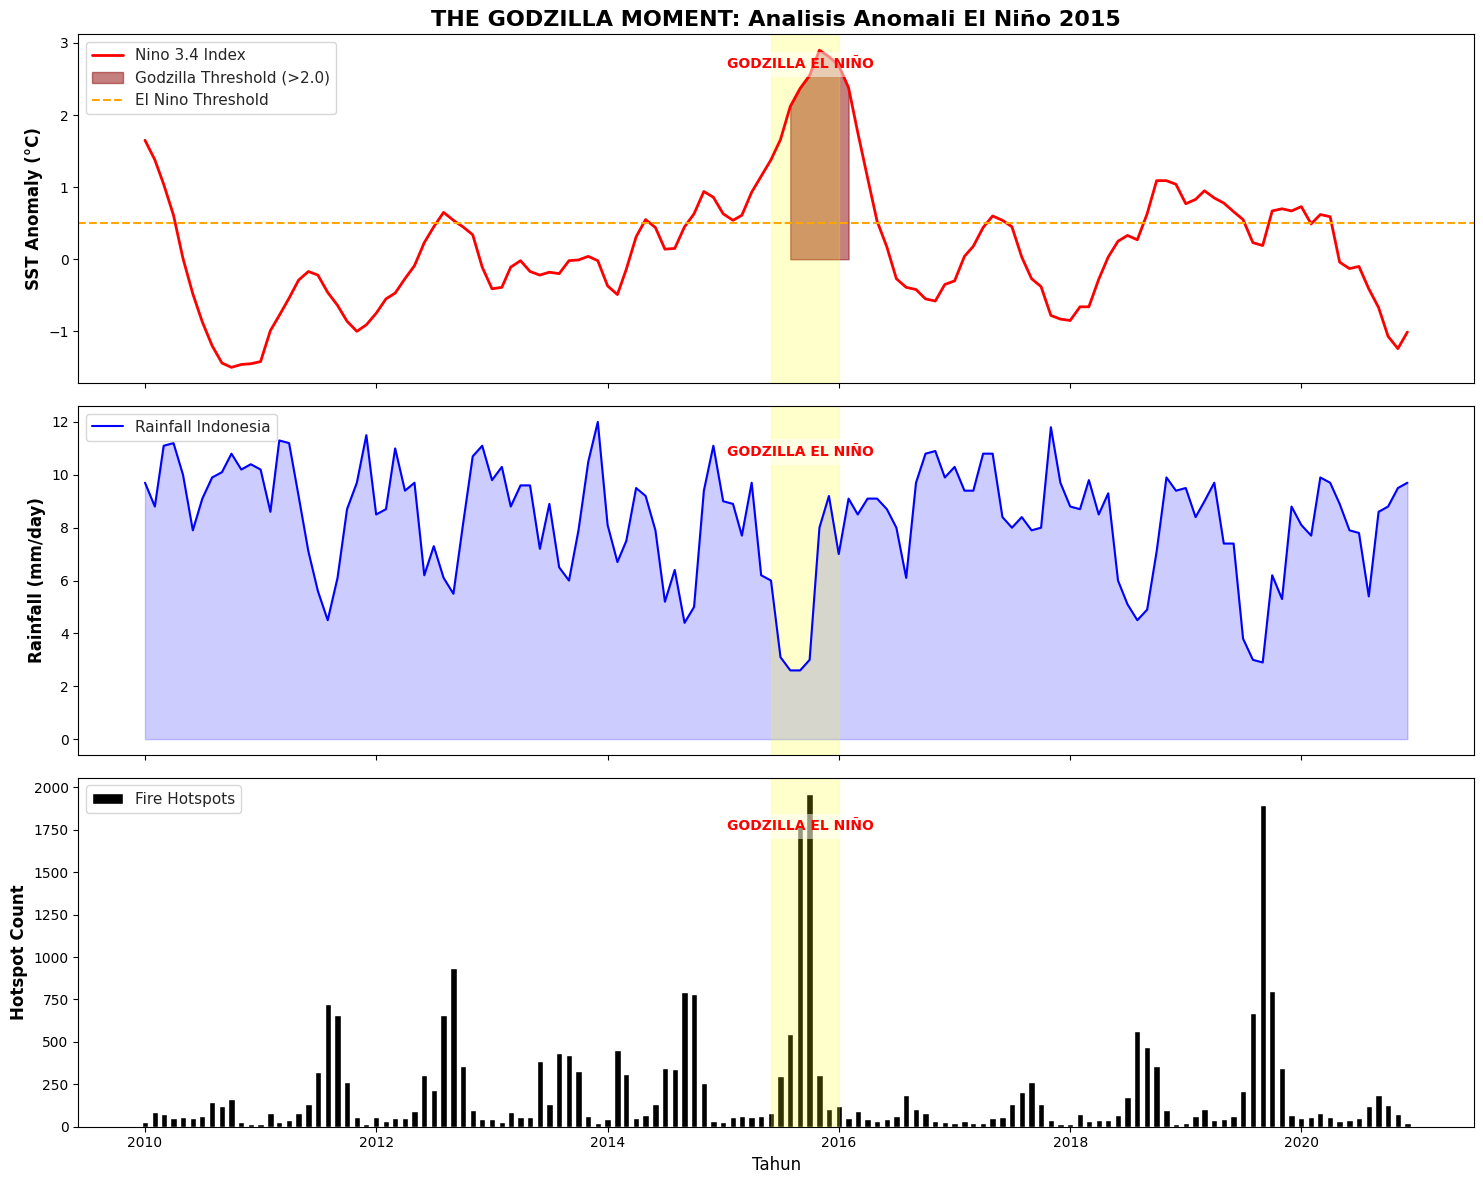

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset Master Bulanan
# Pastikan file ini sudah ada di direktori kerja Anda
df = pd.read_csv('CLIMATE_HAZARD_PREDICTOR_ID.csv')
df['Tanggal'] = pd.to_datetime(df['Tanggal'])

# 2. Filter data (2010 - 2020) agar perbandingan Godzilla 2015 terlihat jelas
df_viz = df[(df['Tanggal'] >= '2010-01-01') & (df['Tanggal'] <= '2020-12-31')].copy()

# 3. Setup Plotting
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
sns.set_theme(style="whitegrid")

# --- PLOT 1: ANOMALI NINO 3.4 (PEMICU) ---
ax1.plot(df_viz['Tanggal'], df_viz['Nino34_Anomaly'], color='red', linewidth=2, label='Nino 3.4 Index')
ax1.fill_between(df_viz['Tanggal'], 0, df_viz['Nino34_Anomaly'], 
                 where=(df_viz['Nino34_Anomaly'] >= 2.0), color='darkred', alpha=0.5, label='Godzilla Threshold (>2.0)')
ax1.axhline(0.5, color='orange', linestyle='--', label='El Nino Threshold')
ax1.set_ylabel('SST Anomaly (°C)', fontsize=12, fontweight='bold')
ax1.set_title('THE GODZILLA MOMENT: Analisis Anomali El Niño 2015', fontsize=16, fontweight='bold')
ax1.legend(loc='upper left')

# --- PLOT 2: CURAH HUJAN INDONESIA (DAMPAK 1) ---
ax2.plot(df_viz['Tanggal'], df_viz['Curah_Indonesia'], color='blue', linewidth=1.5, label='Rainfall Indonesia')
ax2.fill_between(df_viz['Tanggal'], df_viz['Curah_Indonesia'], color='blue', alpha=0.2)
ax2.set_ylabel('Rainfall (mm/day)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper left')

# --- PLOT 3: HOTSPOT INDONESIA (DAMPAK 2) ---
# Menggunakan bar chart untuk hotspot agar terlihat seperti ledakan titik api
ax3.bar(df_viz['Tanggal'], df_viz['Hotspot_Indonesia'], color='black', width=20, label='Fire Hotspots')
ax3.set_ylabel('Hotspot Count', fontsize=12, fontweight='bold')
ax3.set_xlabel('Tahun', fontsize=12)
ax3.legend(loc='upper left')

# --- 4. PERBAIKAN: HIGHLIGHT MOMENT 2015 ---
# Kita ubah string tanggal menjadi pd.to_datetime agar tidak error lagi
h_start = pd.to_datetime('2015-06-01')
h_end = pd.to_datetime('2016-01-01')
t_pos = pd.to_datetime('2015-09-01')

for ax in [ax1, ax2, ax3]:
    # Menambahkan kotak kuning transparan
    ax.axvspan(h_start, h_end, color='yellow', alpha=0.2)
    
    # Menambahkan teks keterangan
    # Menggunakan ax.text lebih stabil untuk sumbu waktu
    y_limit = ax.get_ylim()[1]
    ax.text(t_pos, y_limit * 0.85, 'GODZILLA EL NIÑO', 
            fontsize=10, color='red', fontweight='bold', ha='center', 
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='none'))

plt.tight_layout()
plt.show()

# Visualisasi "The Domino Effect" (Correlation Heatmap)

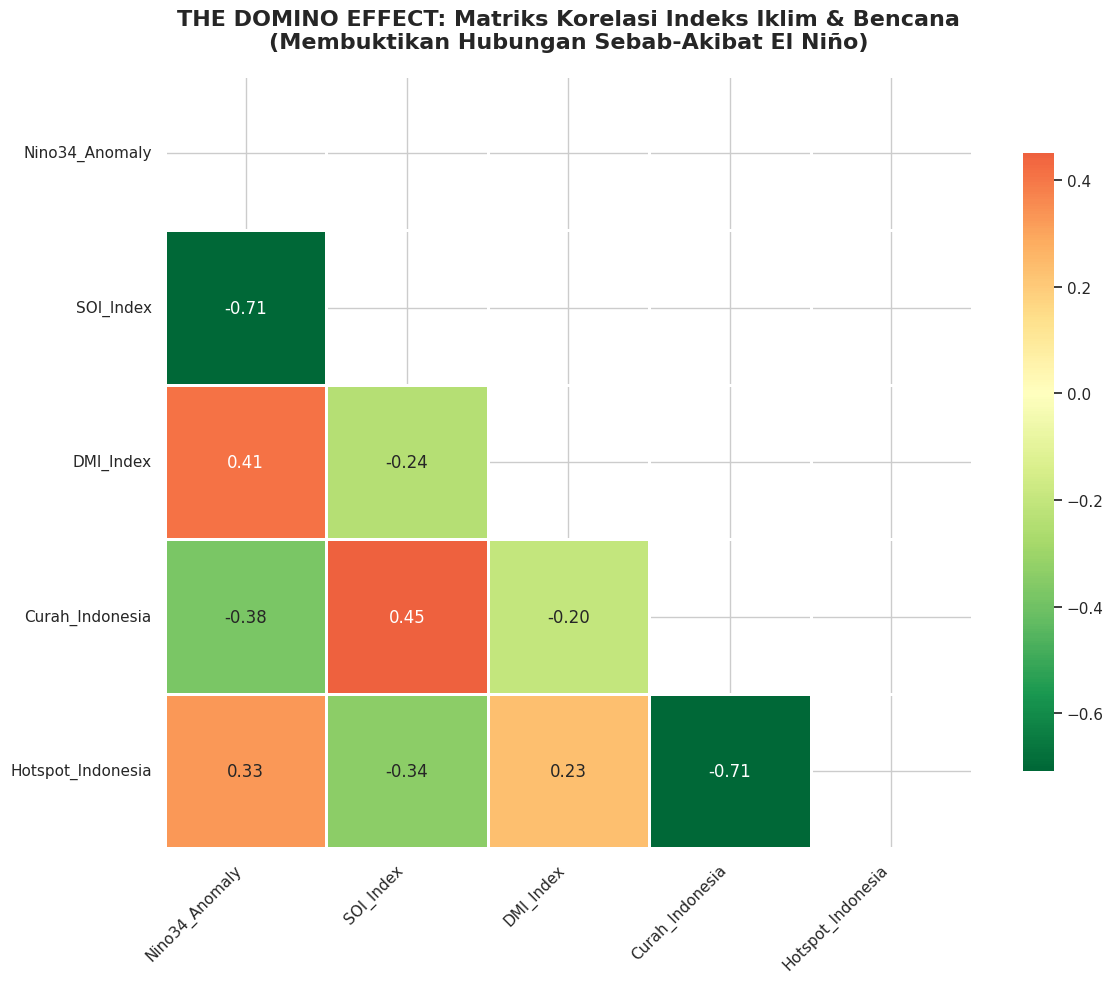

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Load Dataset Master Bulanan
df = pd.read_csv('CLIMATE_HAZARD_PREDICTOR_ID.csv')

# 2. Pilih variabel kunci untuk melihat "Efek Domino"
# Kita sertakan juga variabel LAG untuk melihat efek tunda (misal: suhu laut 3 bulan lalu vs kondisi sekarang)
columns_to_corr = [
    'Nino34_Anomaly', 'SOI_Index', 'DMI_Index', 
    'Curah_Indonesia', 'Hotspot_Indonesia',
    'Nino34_Anomaly_Lag3'  # Efek tunda 3 bulan
]

# Pastikan kolom tersedia sebelum menghitung korelasi
existing_cols = [c for c in columns_to_corr if c in df.columns]
df_corr = df[existing_cols].corr()

# 3. Setup Visualisasi Heatmap
plt.figure(figsize=(12, 10))

# Membuat mask untuk menutupi bagian atas (agar lebih rapi/tidak double)
mask = np.triu(np.ones_like(df_corr, dtype=bool))

# Menggambar Heatmap
heatmap = sns.heatmap(df_corr, 
                      mask=mask, 
                      annot=True,          # Menampilkan angka korelasi
                      fmt=".2f",           # 2 angka di belakang koma
                      cmap='RdYlGn_r',     # Warna Merah (Bahaya) ke Hijau (Aman)
                      center=0, 
                      linewidths=1, 
                      cbar_kws={"shrink": .8})

# 4. Labeling & Estetika
plt.title('THE DOMINO EFFECT: Matriks Korelasi Indeks Iklim & Bencana\n(Membuktikan Hubungan Sebab-Akibat El Niño)', 
          fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Visualisasi "The Lag Proof" (Cross-Correlation)

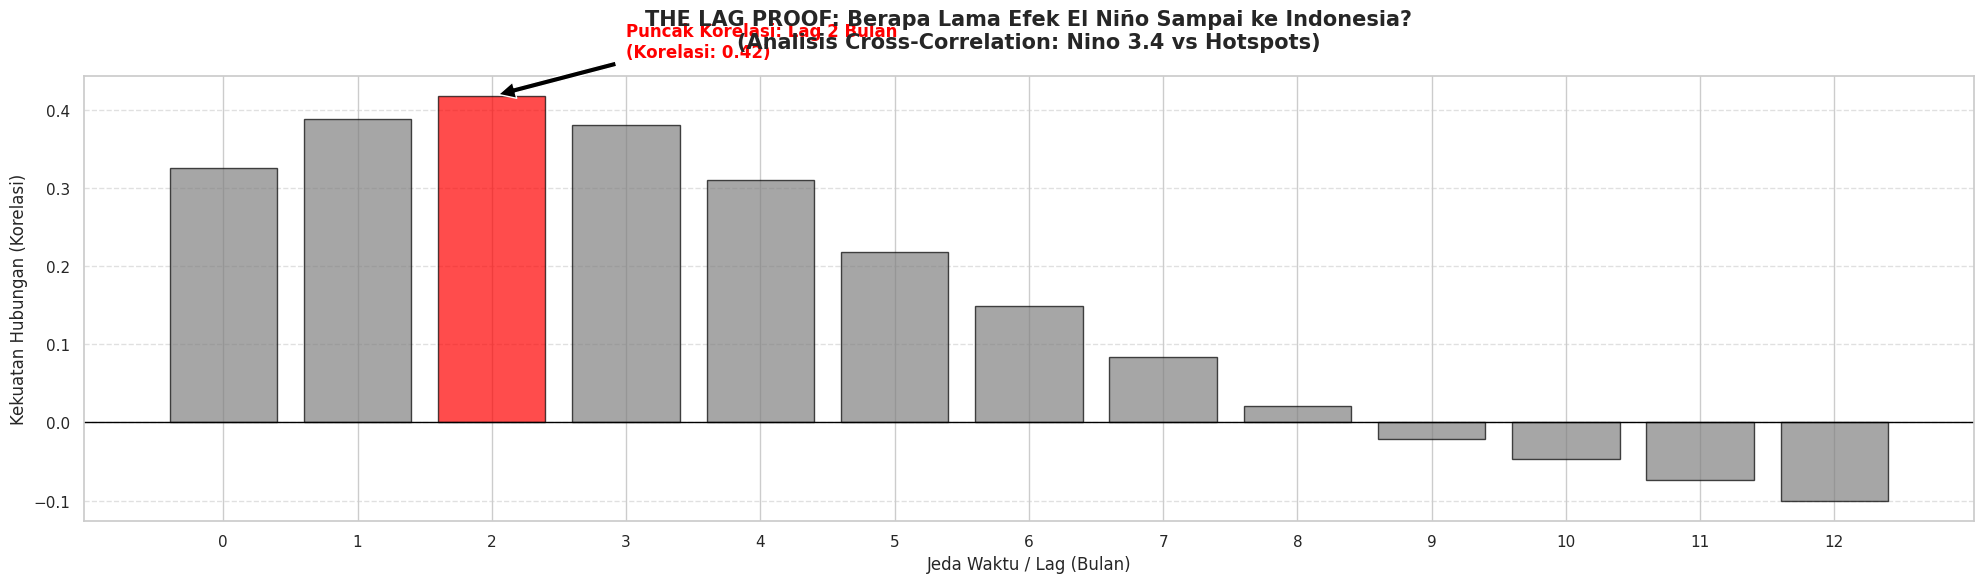

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import numpy as np

# 1. Load Dataset Master Bulanan
df = pd.read_csv('CLIMATE_HAZARD_PREDICTOR_ID.csv')

# 2. Menyiapkan data (kita gunakan Nino34 Anomaly dan Hotspot Indonesia)
# Kita hilangkan nilai NaN jika ada
data = df[['Nino34_Anomaly', 'Hotspot_Indonesia']].dropna()

# Standardisasi data agar skala sebanding (Z-score)
nino_std = (data['Nino34_Anomaly'] - data['Nino34_Anomaly'].mean()) / data['Nino34_Anomaly'].std()
hotspot_std = (data['Hotspot_Indonesia'] - data['Hotspot_Indonesia'].mean()) / data['Hotspot_Indonesia'].std()

# 3. Menghitung Cross-Correlation
# Kita akan melihat korelasi dari lag 0 sampai 12 bulan
lags = np.arange(0, 13)
correlations = [nino_std.corr(hotspot_std.shift(l)) for l in lags]

# 4. Visualisasi "The Lag Proof"
plt.figure(figsize=(20, 6))
colors = ['grey' if c < max(correlations) else 'red' for c in correlations]

plt.bar(lags, correlations, color=colors, alpha=0.7, edgecolor='black')
plt.axhline(0, color='black', linewidth=1)

# Highlight Lag Tertinggi
max_lag = lags[np.argmax(correlations)]
max_corr = max(correlations)

plt.annotate(f'Puncak Korelasi: Lag {max_lag} Bulan\n(Korelasi: {max_corr:.2f})', 
             xy=(max_lag, max_corr), xytext=(max_lag+1, max_corr+0.05),
             arrowprops=dict(facecolor='black', shrink=0.05),
             fontsize=12, fontweight='bold', color='red')

# Labeling
plt.title('THE LAG PROOF: Berapa Lama Efek El Niño Sampai ke Indonesia?\n(Analisis Cross-Correlation: Nino 3.4 vs Hotspots)', 
          fontsize=15, fontweight='bold', pad=20)
plt.xlabel('Jeda Waktu / Lag (Bulan)', fontsize=12)
plt.ylabel('Kekuatan Hubungan (Korelasi)', fontsize=12)
plt.xticks(lags)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Visualisasi "Ecological Vital Signs" (Scatter Plot + Trendline)

/usr/local/lib/python3.12/dist-packages/matplotlib/text.py:1475: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  x = float(self.convert_xunits(x))
/usr/local/lib/python3.12/dist-packages/matplotlib/text.py:1477: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  y = float(self.convert_yunits(y))


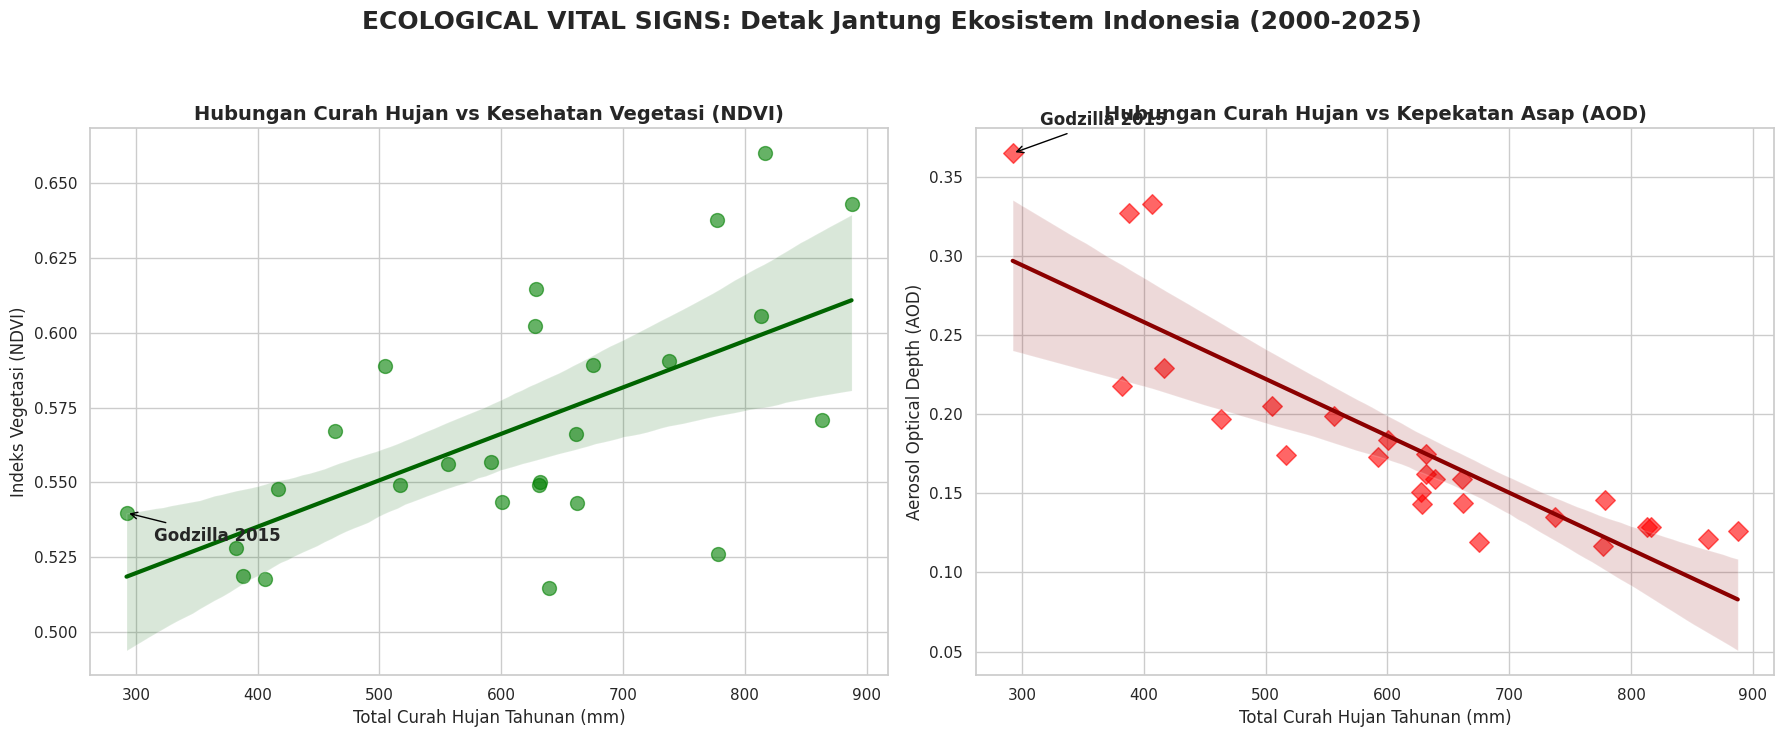

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset Master Tahunan
df_yearly = pd.read_csv('ECO_SYSTEM_VITAL_SIGNS_ID.csv')

# 2. Setup Figure dengan 2 Subplot (Sampingan)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
sns.set_theme(style="whitegrid")

# --- PLOT 1: Hubungan Hujan & Kesehatan Hutan (NDVI) ---
# Kita ingin melihat apakah hutan lebih hijau saat banyak hujan
sns.regplot(data=df_yearly, x='Total_Curah_Hujan_mm', y='Nilai_NDVI', 
            ax=ax1, color='green', marker='o', 
            scatter_kws={'s': 100, 'alpha': 0.6}, 
            line_kws={'color': 'darkgreen', 'lw': 3})

ax1.set_title('Hubungan Curah Hujan vs Kesehatan Vegetasi (NDVI)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Total Curah Hujan Tahunan (mm)', fontsize=12)
ax1.set_ylabel('Indeks Vegetasi (NDVI)', fontsize=12)

# --- PLOT 2: Hubungan Hujan & Polusi Asap (AOD) ---
# Kita ingin melihat apakah asap berkurang saat hujan tinggi
sns.regplot(data=df_yearly, x='Total_Curah_Hujan_mm', y='Rata_rata_AOD', 
            ax=ax2, color='red', marker='D', 
            scatter_kws={'s': 100, 'alpha': 0.6}, 
            line_kws={'color': 'darkred', 'lw': 3})

ax2.set_title('Hubungan Curah Hujan vs Kepekatan Asap (AOD)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Total Curah Hujan Tahunan (mm)', fontsize=12)
ax2.set_ylabel('Aerosol Optical Depth (AOD)', fontsize=12)

# 3. Memberikan Label pada Titik Tahun Ekstrem (Contoh: Godzilla 2015)
# Cari baris tahun 2015
row_2015 = df_yearly[df_yearly['Tahun'] == 2015]
if not row_2015.empty:
    ax1.annotate('Godzilla 2015', 
                 xy=(row_2015['Total_Curah_Hujan_mm'], row_2015['Nilai_NDVI']), 
                 xytext=(20, -20), textcoords='offset points',
                 arrowprops=dict(arrowstyle='->', color='black'), fontweight='bold')
    
    ax2.annotate('Godzilla 2015', 
                 xy=(row_2015['Total_Curah_Hujan_mm'], row_2015['Rata_rata_AOD']), 
                 xytext=(20, 20), textcoords='offset points',
                 arrowprops=dict(arrowstyle='->', color='black'), fontweight='bold')

plt.suptitle('ECOLOGICAL VITAL SIGNS: Detak Jantung Ekosistem Indonesia (2000-2025)', 
             fontsize=18, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()